# Lab 5 — Transformers : l'attention de zéro, un mini-Transformer, CamemBERT

**ENSIM · 5A ASTRE · De l'IA au LLM agentique · Séance 5**
*Bassem Ben Hamed & Ali Khalfallah*

Ce lab se fait **en autonomie, après la séance 5**. Il valide la séance : chaque exemple numérique des diapositives est recalculé ici, puis mis en œuvre sur le fil rouge B (classification d'intention sur MASSIVE fr-FR), où l'on compare un **GRU** (séance 4), un **mini-Transformer** codé de zéro et **CamemBERT** fine-tuné.

## Objectifs

À la fin du lab, vous savez :

1. coder l'**attention par produit scalaire mis à l'échelle** en NumPy, puis la visualiser (*heatmap*) sur « allume la lumière du salon » ;
2. expliquer pourquoi on divise par $\sqrt{d_k}$, et construire l'**encodage positionnel** sinusoïdal et le **masque causal** ;
3. compter les **paramètres** d'un bloc Transformer ($\approx 12\,d^2$) et le **coût en $n^2$** de l'attention ;
4. coder un **mini-encodeur Transformer** et l'entraîner sur MASSIVE fr-FR ;
5. **fine-tuner CamemBERT** avec une boucle PyTorch explicite, puis comparer au GRU et au mini-Transformer (exactitude, paramètres, temps) ;
6. (optionnel) enchaîner **voix → Whisper → texte → intention** ;
7. estimer la mémoire et les MAC d'un Transformer sur un **STM32F446**.

## Prérequis et environnement

- Séances 3 et 4 (rétropropagation, RNN/LSTM/GRU), notions de PyTorch.
- **Google Colab gratuit, GPU T4 recommandé** (Exécution → Modifier le type d'exécution). Le code choisit le périphérique dans l'ordre CUDA, MPS, CPU. **Sur CPU**, le fine-tuning de CamemBERT est réduit à un sous-ensemble du jeu d'entraînement. Durée sur un Mac M4 Pro (GPU MPS) : de 20 à 30 minutes, dont la plus grande part pour le fine-tuning de CamemBERT ; sur un T4 de Colab, elle n'a pas été mesurée.

## Plan

| Partie | Contenu |
|---|---|
| 1 | Rappel des formules |
| A | Recalculer les exemples numériques des diapositives |
| B | Expériences : attention de zéro, mini-Transformer, CamemBERT, voix vers intention, cible embarquée |
| C | Exercices de validation, vérifiés automatiquement |
| | Corrigé |

> **Données** : *Amazon MASSIVE 1.1*, partition fr-FR (FitzGerald et al., 2022), licence CC BY 4.0, partition officielle `train` (11 514 phrases), `dev` (2 033), `test` (2 974) ; 60 intentions, dont 9 `iot_*`. **Modèles** : `almanach/camembert-base` (Martin et al., 2020, licence MIT), `openai/whisper-tiny` (Radford et al., 2022, licence Apache 2.0), `facebook/mms-tts-fra` (synthèse vocale, pour l'étape optionnelle ; licence CC BY-NC 4.0, usage non commercial).

## 1. Rappel des formules

| Notion | Formule |
|---|---|
| Attention | $\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\Big(\dfrac{QK^\top}{\sqrt{d_k}}\Big)V$ |
| Variance des scores | $\mathrm{Var}(\mathbf{q}\cdot\mathbf{k}) = d_k$ si les composantes sont indépendantes, centrées, de variance 1 |
| Multi-têtes | $\mathrm{MultiHead}(X) = \mathrm{Concat}(\mathrm{head}_1,\dots,\mathrm{head}_h)\,W^O$, $\;d_k = d_{\text{model}}/h$ |
| Encodage positionnel | $\mathrm{PE}(pos,2i)=\sin\big(pos/10000^{2i/d}\big)$, $\;\mathrm{PE}(pos,2i+1)=\cos\big(pos/10000^{2i/d}\big)$ |
| Masque causal | on ajoute $-\infty$ au-dessus de la diagonale avant le softmax |
| Paramètres d'un bloc | attention $4d^2$ + FFN $8d^2$ $\approx 12\,d^2$ (biais et LayerNorm négligés) |
| Coût de l'attention | $n^2$ scores par tête et par couche ; $QK^\top$ : $n^2 d_k$ MAC |
| MAC d'une couche | projections $4nd^2$, scores et somme $2n^2d$, FFN $8nd^2$ |
| Distillation | $\mathrm{softmax}(\mathbf{z}/T)$ : plus $T$ est grand, plus la distribution est douce |
| Mémoire des poids | $\text{paramètres} \times \text{octets par paramètre}$ |

### Installation et imports

Sur Colab, `torch` et `transformers` sont déjà installés.

In [1]:
try:
    import transformers
except ImportError:
    %pip install -q transformers
    import transformers

import collections, io, json, math, os, re, tarfile, tempfile, time, urllib.request, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": False})
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
T0 = time.time()
CACHE = os.path.join(tempfile.gettempdir(), "lab4_cache")   # partagé avec le lab 4 : MASSIVE n'est téléchargé qu'une fois
os.makedirs(CACHE, exist_ok=True)

def choisir_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")
DEVICE = choisir_device()
print("torch", torch.__version__, "| transformers", transformers.__version__, "| périphérique :", DEVICE)

def softmax_np(z, axis=-1):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max(axis=axis, keepdims=True))
    return e / e.sum(axis=axis, keepdims=True)

def nb_params(model):
    return sum(p.numel() for p in model.parameters())

torch 2.10.0 | transformers 5.3.0 | périphérique : mps


## Partie A — Recalculer les exemples des diapositives

### A1. L'attention sur « allume la lumière » (3 tokens, $d_k = 2$)

Dimension 1 : « action » ; dimension 2 : « objet ». « allume » cherche un objet, « lumière » cherche une action ; l'article « la » a une clé et une valeur nulles. On prend $V = K$.

In [2]:
tokens = ["allume", "la", "lumière"]
Q = np.array([[0, 2], [0, 1], [2, 0]], dtype=float)
K = np.array([[1, 0], [0, 0], [0, 1]], dtype=float)
V = K.copy()
dk = Q.shape[1]

S = Q @ K.T
print("S = Q K^T =\n", S)
print("\nS / sqrt(dk) =\n", S / math.sqrt(dk))
A = softmax_np(S / math.sqrt(dk))
print("\nA = softmax ligne par ligne =\n", A.round(3), "\nsommes des lignes :", A.sum(axis=1))
Z = A @ V
print("\nZ = A V =\n", Z.round(3))

S = Q K^T =
 [[0. 0. 2.]
 [0. 0. 1.]
 [2. 0. 0.]]

S / sqrt(dk) =
 [[0.     0.     1.4142]
 [0.     0.     0.7071]
 [1.4142 0.     0.    ]]

A = softmax ligne par ligne =
 [[0.164 0.164 0.673]
 [0.248 0.248 0.503]
 [0.673 0.164 0.164]] 
sommes des lignes : [1. 1. 1.]

Z = A V =
 [[0.164 0.673]
 [0.248 0.503]
 [0.673 0.164]]


### A2. Pourquoi diviser par $\sqrt{d_k}$ ?

Avec des composantes indépendantes, centrées, de variance 1, la variance de $\mathbf{q}\cdot\mathbf{k}$ vaut $d_k$. On vérifie par simulation avec $d_k = 64$ (écart-type théorique : 8), puis on compare le softmax avec et sans division.

In [3]:
rng = np.random.default_rng(0)
n_tir, d_k = 20000, 64
q = rng.standard_normal((n_tir, d_k)); k = rng.standard_normal((n_tir, d_k))
s = (q * k).sum(axis=1)
print(f"d_k = {d_k} : variance de q.k = {s.var():.1f} (théorie : {d_k}), écart-type = {s.std():.2f} (théorie : {math.sqrt(d_k):.0f})")
print("softmax(8, 0) sans division :", softmax_np([8, 0]).round(4))
print("softmax(1, 0) avec division par 8 :", softmax_np([1, 0]).round(3))

d_k = 64 : variance de q.k = 64.6 (théorie : 64), écart-type = 8.04 (théorie : 8)
softmax(8, 0) sans division : [0.9997 0.0003]
softmax(1, 0) avec division par 8 : [0.731 0.269]


### A3. Plusieurs têtes : combien de paramètres ?

$d_{\text{model}} = 512$, $h = 8$ têtes de dimension $d_k = 64$. On compare le compte de la diapositive (biais exclus) à `nn.MultiheadAttention`.

In [4]:
d_model, h = 512, 8
formule = 3 * h * (d_model * (d_model // h)) + d_model * d_model
mha = nn.MultiheadAttention(d_model, h, batch_first=True)
print(f"3 x {h} x ({d_model} x {d_model // h}) + {d_model} x {d_model} = {formule:,}  (= 4 x 512^2 = {4 * d_model ** 2:,}), biais exclus".replace(",", " "))
print(f"nn.MultiheadAttention : {nb_params(mha):,} paramètres (= {formule:,} + 4 x 512 biais)".replace(",", " "))
x = torch.randn(1, 10, d_model)
sortie, poids = mha(x, x, x, need_weights=True)
print("entrée (1, n = 10, 512) -> sortie", tuple(sortie.shape), "; matrice d'attention", tuple(poids.shape))

3 x 8 x (512 x 64) + 512 x 512 = 1 048 576  (= 4 x 512^2 = 1 048 576)  biais exclus
nn.MultiheadAttention : 1 050 624 paramètres (= 1 048 576 + 4 x 512 biais)
entrée (1, n = 10, 512) -> sortie (1, 10, 512) ; matrice d'attention (1, 10, 10)


### A4. L'encodage positionnel

On construit $\mathrm{PE}$ pour $d_{\text{model}} = 4$ (deux fréquences : $1$ et $1/100$), puis on vérifie que **sans** encodage positionnel, permuter les mots permute simplement les sorties : l'attention ne voit pas l'ordre.

In [5]:
def pe_sinus(positions, d):
    pe = np.zeros((len(positions), d))
    for i in range(d // 2):
        w = 1.0 / 10000 ** (2 * i / d)
        pe[:, 2 * i] = np.sin(np.asarray(positions) * w)
        pe[:, 2 * i + 1] = np.cos(np.asarray(positions) * w)
    return pe

print(pd.DataFrame(pe_sinus(range(4), 4), columns=["sin(pos)", "cos(pos)", "sin(pos/100)", "cos(pos/100)"]).round(4).to_string())

rng = np.random.default_rng(1)
X = rng.standard_normal((5, 8)); Wq, Wk, Wv = (rng.standard_normal((8, 8)) for _ in range(3))
def attention_complete(X):
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    return softmax_np(Q @ K.T / math.sqrt(8)) @ V
perm = np.array([4, 3, 2, 1, 0])
print("\nsans PE : sortie(permutation(X)) = permutation(sortie(X)) ?", np.allclose(attention_complete(X[perm]), attention_complete(X)[perm]))
pe = pe_sinus(range(5), 8)
print("avec PE : sortie(permutation(X + PE)) = permutation(sortie(X + PE)) ?", np.allclose(attention_complete((X + pe)[perm]), attention_complete(X + pe)[perm]))
print("avec PE, les mots permutés (PE restant à sa place) donnent une autre sortie :", not np.allclose(attention_complete(X[perm] + pe), attention_complete(X + pe)[perm]))

   sin(pos)  cos(pos)  sin(pos/100)  cos(pos/100)
0    0.0000    1.0000          0.00        1.0000
1    0.8415    0.5403          0.01        1.0000
2    0.9093   -0.4161          0.02        0.9998
3    0.1411   -0.9900          0.03        0.9996

sans PE : sortie(permutation(X)) = permutation(sortie(X)) ? True
avec PE : sortie(permutation(X + PE)) = permutation(sortie(X + PE)) ? True
avec PE, les mots permutés (PE restant à sa place) donnent une autre sortie : True


### A5. Paramètres d'un bloc : $\approx 12\,d^2$

BERT-base : $d = 768$, 12 blocs. On instancie `BertModel` **sans télécharger de poids** (configuration seule) et on compte.

In [6]:
from transformers import BertConfig, BertModel
bert = BertModel(BertConfig(), add_pooling_layer=False)
bloc = bert.encoder.layer[0]
d = 768
print(f"12 d^2 = 12 x {d}^2 = {12 * d ** 2:,}".replace(",", " "))
print(f"un bloc BERT-base (avec biais et LayerNorm) : {nb_params(bloc):,}".replace(",", " "))
print(f"12 blocs : 12 x {12 * d ** 2:,} = {12 * 12 * d ** 2:,} (formule) ; {nb_params(bert.encoder):,} (exact)".replace(",", " "))
print(f"embeddings : {nb_params(bert.embeddings):,} ; modèle complet : {nb_params(bert):,} (BERT-base : 110 M avec le pooler)".replace(",", " "))
attn = nb_params(bloc.attention); ffn = nb_params(bloc.intermediate) + nb_params(bloc.output.dense)
print(f"part du FFN dans un bloc : {ffn / nb_params(bloc):.1%} (les 2/3 environ)")

12 d^2 = 12 x 768^2 = 7 077 888
un bloc BERT-base (avec biais et LayerNorm) : 7 087 872
12 blocs : 12 x 7 077 888 = 84 934 656 (formule) ; 85 054 464 (exact)
embeddings : 23 837 184 ; modèle complet : 108 891 648 (BERT-base : 110 M avec le pooler)
part du FFN dans un bloc : 66.6% (les 2/3 environ)


### A6. Un coût quadratique

Le nombre de scores d'attention est $n^2$ par tête et par couche.

In [7]:
for n in (512, 4096):
    print(f"n = {n:5d} : {n ** 2:>11,} scores = {n ** 2 * 4 / 2 ** 20:6.1f} Mio en float32".replace(",", " "))
print(f"rapport : ({4096}/{512})^2 = {(4096 / 512) ** 2:.0f}")
print(f"12 têtes x 12 couches à n = 4096 : {12 * 12 * 4096 ** 2 * 4 / 2 ** 30:.1f} Gio")

n =   512 :     262 144 scores =    1.0 Mio en float32
n =  4096 :  16 777 216 scores =   64.0 Mio en float32
rapport : (4096/512)^2 = 64
12 têtes x 12 couches à n = 4096 : 9.0 Gio


### A7. Le masquage de BERT (15 %, puis 80/10/10) et le masque causal de GPT

In [8]:
print("lot de 1000 tokens : 15 % =", int(0.15 * 1000), "à prédire ; 80 % ->", int(0.8 * 150), "[MASK] ; 10 % ->", int(0.1 * 150), "aléatoires ; 10 % ->", int(0.1 * 150), "inchangés")
rng = np.random.default_rng(0)
tire = rng.random(100000) < 0.15
print(f"simulation sur 100 000 tokens : {tire.mean():.3f} tirés (théorie 0,150)")

S4 = np.array([[2, 1, 0, 1], [1, 2, 1, 0], [0, 1, 2, 1], [1, 0, 1, 2]], dtype=float)
masque = np.triu(np.full((4, 4), -np.inf), k=1)
print("\nscores + masque causal :\n", S4 + masque)
print("\nsoftmax ligne par ligne :\n", softmax_np(S4 + masque).round(4))

lot de 1000 tokens : 15 % = 150 à prédire ; 80 % -> 120 [MASK] ; 10 % -> 15 aléatoires ; 10 % -> 15 inchangés
simulation sur 100 000 tokens : 0.152 tirés (théorie 0,150)

scores + masque causal :
 [[  2. -inf -inf -inf]
 [  1.   2. -inf -inf]
 [  0.   1.   2. -inf]
 [  1.   0.   1.   2.]]

softmax ligne par ligne :
 [[1.     0.     0.     0.    ]
 [0.2689 0.7311 0.     0.    ]
 [0.09   0.2447 0.6652 0.    ]
 [0.1966 0.0723 0.1966 0.5344]]


### A8. Vision et audio : les dimensions des diapositives

In [9]:
print("ViT-Base : 224/16 =", 224 // 16, "patchs par côté ;", (224 // 16) ** 2, "patchs ; avec [CLS] :", (224 // 16) ** 2 + 1, "tokens")
print("  valeurs par patch : 16 x 16 x 3 =", 16 * 16 * 3, "; scores d'attention par tête : 197^2 =", 197 ** 2)
print("Whisper : 30 s à 16 kHz =", 30 * 16000, "échantillons ; fenêtre 25 ms =", int(0.025 * 16000), "; pas 10 ms =", int(0.010 * 16000))
print("  trames :", 30 * 16000 // 160, "sur 80 canaux Mel ; après la convolution de pas 2 :", 30 * 16000 // 160 // 2, "positions")

ViT-Base : 224/16 = 14 patchs par côté ; 196 patchs ; avec [CLS] : 197 tokens
  valeurs par patch : 16 x 16 x 3 = 768 ; scores d'attention par tête : 197^2 = 38809
Whisper : 30 s à 16 kHz = 480000 échantillons ; fenêtre 25 ms = 400 ; pas 10 ms = 160
  trames : 3000 sur 80 canaux Mel ; après la convolution de pas 2 : 1500 positions


### A9. Distillation et mémoire des poids

In [10]:
z = np.array([2.0, 1.0, 0.0])
print("T = 1 :", softmax_np(z).round(4), "   T = 2 :", softmax_np(z / 2).round(3))
print("\nMémoire des poids (paramètres x octets) :")
for nom, p in [("Whisper tiny", 39e6), ("DistilBERT", 66e6), ("BERT-base, CamemBERT-base", 110e6)]:
    print(f"  {nom:28s} {p / 1e6:5.0f} M : float32 {4 * p / 1e6:6.0f} Mo, int8 {p / 1e6:5.0f} Mo")

T = 1 : [0.6652 0.2447 0.09  ]    T = 2 : [0.506 0.307 0.186]

Mémoire des poids (paramètres x octets) :
  Whisper tiny                    39 M : float32    156 Mo, int8    39 Mo
  DistilBERT                      66 M : float32    264 Mo, int8    66 Mo
  BERT-base, CamemBERT-base      110 M : float32    440 Mo, int8   110 Mo


### A10. Un Transformer sur cible embarquée

Commande vocale de $n = 32$ tokens, $d = 128$, $d_{ff} = 512$, 4 têtes, 2 couches. STM32F446 : Cortex-M4 à 180 MHz, 512 Ko de Flash, 128 Ko de SRAM.

In [11]:
n, d, tetes, couches = 32, 128, 4, 2
SRAM, FREQ = 128 * 1024, 180e6
print(f"matrice d'attention : {n}^2 x 4 octets = {n * n * 4} octets = {n * n * 4 / 1024:.0f} Ko par tête ; {tetes} têtes : {tetes * n * n * 4 / 1024:.0f} Ko")
print(f"plus grand n pour une tête dans 128 Ko : float32 {math.sqrt(SRAM / 4):.0f} tokens ; int8 {math.sqrt(SRAM):.0f} tokens")
proj, scores, ffn_mac = 4 * n * d * d, 2 * n * n * d, 8 * n * d * d
print(f"MAC par couche : projections {proj / 1e6:.2f} M + scores et somme {scores / 1e6:.3f} M + FFN {ffn_mac / 1e6:.2f} M = {(proj + scores + ffn_mac) / 1e6:.2f} M")
print(f"{couches} couches : {couches * (proj + scores + ffn_mac) / 1e6:.1f} M MAC, soit {couches * (proj + scores + ffn_mac) / FREQ * 1e3:.0f} ms à 180 MHz pour 1 MAC par cycle")

matrice d'attention : 32^2 x 4 octets = 4096 octets = 4 Ko par tête ; 4 têtes : 16 Ko
plus grand n pour une tête dans 128 Ko : float32 181 tokens ; int8 362 tokens
MAC par couche : projections 2.10 M + scores et somme 0.262 M + FFN 4.19 M = 6.55 M
2 couches : 13.1 M MAC, soit 73 ms à 180 MHz pour 1 MAC par cycle


## Partie B — Expériences

### B1. L'attention codée de zéro, sur « allume la lumière du salon »

On étend l'exemple à 5 tokens et 3 dimensions : « action », « objet », « lieu ». Les vecteurs sont **choisis à la main** pour l'illustration : ce n'est pas un modèle entraîné. On code une fonction d'attention générale (avec masque optionnel) et on trace la matrice $A$.

matrice d'attention A (lignes : qui regarde ; colonnes : qui est regardé) :
          allume     la  lumière     du  salon
allume    0.139  0.139    0.442  0.139  0.139
la        0.173  0.173    0.308  0.173  0.173
lumière   0.399  0.126    0.126  0.126  0.224
du        0.173  0.173    0.173  0.173  0.308
salon     0.173  0.173    0.308  0.173  0.173


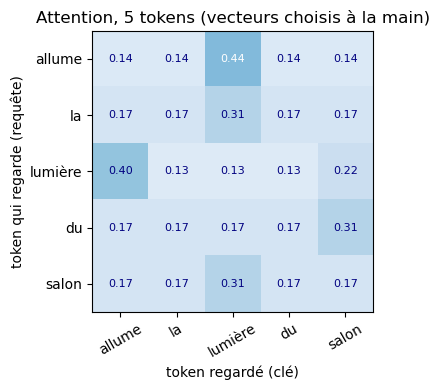


avec le masque causal (un token ne voit que le passé) :
         allume     la  lumière     du  salon
allume    1.000  0.000    0.000  0.000  0.000
la        0.500  0.500    0.000  0.000  0.000
lumière   0.613  0.193    0.193  0.000  0.000
du        0.250  0.250    0.250  0.250  0.000
salon     0.173  0.173    0.308  0.173  0.173


In [12]:
def attention(Q, K, V, masque=None):
    """Attention par produit scalaire mis à l'échelle. masque : booléen, True = position autorisée."""
    dk = Q.shape[-1]
    scores = Q @ K.T / math.sqrt(dk)
    if masque is not None:
        scores = np.where(masque, scores, -np.inf)
    A = softmax_np(scores)
    return A @ V, A

mots = ["allume", "la", "lumière", "du", "salon"]
# colonnes : action, objet, lieu
Q5 = np.array([[0, 2, 0], [0, 1, 0], [2, 0, 1], [0, 0, 1], [0, 1, 0]], dtype=float)   # ce que chaque mot cherche
K5 = np.array([[1, 0, 0], [0, 0, 0], [0, 1, 0], [0, 0, 0], [0, 0, 1]], dtype=float)   # ce que chaque mot offre
V5 = K5.copy()
Z5, A5 = attention(Q5, K5, V5)
print("matrice d'attention A (lignes : qui regarde ; colonnes : qui est regardé) :\n", pd.DataFrame(A5, index=mots, columns=mots).round(3).to_string())

fig, ax = plt.subplots(figsize=(4.6, 4))
im = ax.imshow(A5, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(mots, rotation=30); ax.set_yticks(range(5)); ax.set_yticklabels(mots)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{A5[i, j]:.2f}", ha="center", va="center", color="white" if A5[i, j] > 0.4 else "navy", fontsize=8)
ax.set_xlabel("token regardé (clé)"); ax.set_ylabel("token qui regarde (requête)"); ax.set_title("Attention, 5 tokens (vecteurs choisis à la main)")
plt.tight_layout(); plt.show()
print("\navec le masque causal (un token ne voit que le passé) :")
_, A5c = attention(Q5, K5, V5, masque=np.tril(np.ones((5, 5), dtype=bool)))
print(pd.DataFrame(A5c, index=mots, columns=mots).round(3).to_string())

### B2. L'encodage positionnel vu comme une banque d'oscillateurs

Pour $d_{\text{model}} = 64$ et 32 positions : chaque paire de colonnes $(\sin, \cos)$ est un oscillateur dont la fréquence décroît. Les premières colonnes changent à chaque position, les dernières varient lentement.

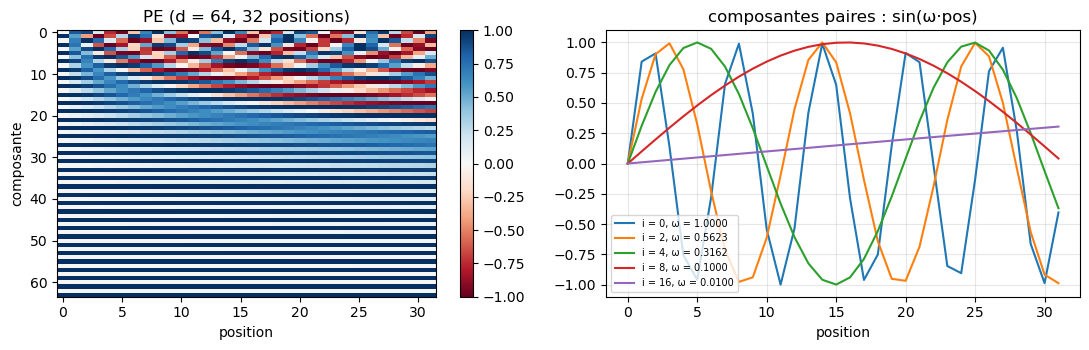

rotation : True


In [13]:
PE = pe_sinus(range(32), 64)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
im = ax[0].imshow(PE.T, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
ax[0].set_xlabel("position"); ax[0].set_ylabel("composante"); ax[0].set_title("PE (d = 64, 32 positions)")
plt.colorbar(im, ax=ax[0])
for i in (0, 2, 4, 8, 16):
    ax[1].plot(PE[:, 2 * i], label=f"i = {i}, ω = {1 / 10000 ** (2 * i / 64):.4f}")
ax[1].set_xlabel("position"); ax[1].set_title("composantes paires : sin(ω·pos)"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
# un décalage est une rotation : PE(p + k) = R(k) PE(p) pour chaque paire (sin, cos)
w, p, k = 1 / 10000 ** (2 * 1 / 64), 5, 3
R = np.array([[math.cos(w * k), math.sin(w * k)], [-math.sin(w * k), math.cos(w * k)]])
print("rotation :", np.allclose(R @ [math.sin(w * p), math.cos(w * p)], [math.sin(w * (p + k)), math.cos(w * (p + k))]))

### B3. MASSIVE fr-FR : chargement et tokenisation

Même chargement et même tokenisation par mots que le lab 4 (le fichier est mis en cache dans un dossier temporaire partagé). **Repli** si le site officiel est indisponible : la version Parquet sur Hugging Face.

In [14]:
URL_MASSIVE = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.1.tar.gz"
URL_PARQUET = "https://huggingface.co/datasets/AmazonScience/massive/resolve/refs%2Fconvert%2Fparquet/fr-FR/{split}/0000.parquet"
FICHIER_FR = os.path.join(CACHE, "massive_fr-FR.jsonl")

def charger_massive():
    if os.path.exists(FICHIER_FR):
        with open(FICHIER_FR, encoding="utf-8") as f:
            return [json.loads(l) for l in f], "cache local"
    try:
        with urllib.request.urlopen(URL_MASSIVE, timeout=180) as r:
            archive = r.read()
        with tarfile.open(fileobj=io.BytesIO(archive), mode="r:gz") as tf:
            texte = tf.extractfile("1.1/data/fr-FR.jsonl").read().decode("utf-8")
        source = "archive officielle"
    except Exception as e:
        print("Archive officielle indisponible :", type(e).__name__, "- repli sur la version Parquet")
        import pyarrow.parquet as pq
        lignes = []
        for split, partition in [("train", "train"), ("validation", "dev"), ("test", "test")]:
            with urllib.request.urlopen(URL_PARQUET.format(split=split), timeout=180) as r:
                t = pq.read_table(io.BytesIO(r.read()))
            noms = json.loads(t.schema.metadata[b"huggingface"])["info"]["features"]["intent"]["names"]
            for utt, intent in zip(t.column("utt").to_pylist(), t.column("intent").to_pylist()):
                lignes.append({"utt": utt, "intent": noms[intent], "partition": partition})
        texte = "\n".join(json.dumps(l, ensure_ascii=False) for l in lignes)
        source = "version Parquet (repli)"
    with open(FICHIER_FR, "w", encoding="utf-8") as f:
        f.write(texte)
    return [json.loads(l) for l in texte.splitlines()], source

lignes, source = charger_massive()
massive = pd.DataFrame([{"utt": l["utt"], "intent": l["intent"], "partition": l["partition"]} for l in lignes])
INTENTS = sorted(massive.intent.unique()); IDX = {k: i for i, k in enumerate(INTENTS)}
tr, dv, te = (massive[massive.partition == p].reset_index(drop=True) for p in ("train", "dev", "test"))
iot_te = te.intent.str.startswith("iot_").values
print("source :", source, "|", {n: len(x) for n, x in [("train", tr), ("dev", dv), ("test", te)]}, "|", len(INTENTS), "intentions")
print("phrases iot_* du test :", int(iot_te.sum()), "(9 intentions iot_*, la prédiction reste choisie parmi les 60)")

def tokeniser(s):
    return re.findall(r"\w+|[^\w\s]", s.lower())
cpt = collections.Counter(t for u in tr.utt for t in tokeniser(u))
vocab = ["<pad>", "<unk>"] + [m for m, _ in cpt.most_common()]
MOT2ID = {m: i for i, m in enumerate(vocab)}
LMAX = max(len(tokeniser(u)) for u in tr.utt)

def encoder(df):
    X = np.zeros((len(df), LMAX), dtype=np.int64); L = np.zeros(len(df), dtype=np.int64)
    for k, u in enumerate(df.utt):
        ids = [MOT2ID.get(t, 1) for t in tokeniser(u)][:LMAX]
        X[k, :len(ids)] = ids; L[k] = len(ids)
    return torch.tensor(X), torch.tensor(L), torch.tensor([IDX[i] for i in df.intent])
Xtr, Ltr, ytr = encoder(tr); Xdv, Ldv, ydv = encoder(dv); Xte, Lte, yte = encoder(te)
masque_iot = torch.tensor(iot_te)
print(f"vocabulaire : {len(vocab)} mots ; longueur maximale : {LMAX} tokens")

def exactitude_generique(predire, X, L, y, masque=None):
    """predire(X, L) -> logits ; renvoie l'exactitude (globale ou restreinte à masque)."""
    with torch.no_grad():
        pred = torch.cat([predire(X[i:i + 256], L[i:i + 256]).argmax(1).cpu() for i in range(0, len(X), 256)])
    ok = (pred == y)
    return (ok.float().mean().item() if masque is None else ok[masque].float().mean().item())

source : cache local | {'train': 11514, 'dev': 2033, 'test': 2974} | 60 intentions
phrases iot_* du test : 220 (9 intentions iot_*, la prédiction reste choisie parmi les 60)
vocabulaire : 6060 mots ; longueur maximale : 40 tokens


### B4. Un mini-encodeur Transformer, codé de zéro

2 blocs, $d = 128$, 4 têtes, $d_{ff} = 512$, pré-normalisation (LayerNorm avant l'attention et avant le FFN), connexions résiduelles, **encodage positionnel sinusoïdal**, *mean pooling* sur les tokens réels, puis `Linear(128, 60)`. Entraînement : AdamW ($\eta = 10^{-3}$, *warmup* de 100 pas, décroissance linéaire), lots de 64, arrêt précoce sur l'exactitude du `dev`, 3 graines.

In [15]:
class AttentionMultiTetes(nn.Module):
    def __init__(self, d, tetes):
        super().__init__()
        assert d % tetes == 0
        self.tetes, self.dk = tetes, d // tetes
        self.qkv = nn.Linear(d, 3 * d)
        self.proj = nn.Linear(d, d)
    def forward(self, x, masque_cles):
        B, n, d = x.shape
        q, k, v = self.qkv(x).view(B, n, 3, self.tetes, self.dk).permute(2, 0, 3, 1, 4)     # chacun : B, têtes, n, dk
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dk)                                # B, têtes, n, n
        scores = scores.masked_fill(~masque_cles[:, None, None, :], float("-inf"))           # les <pad> ne sont pas regardés
        z = F.softmax(scores, dim=-1) @ v
        return self.proj(z.transpose(1, 2).reshape(B, n, d))

class Bloc(nn.Module):
    def __init__(self, d, tetes, dff, p=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.att = AttentionMultiTetes(d, tetes)
        self.ffn = nn.Sequential(nn.Linear(d, dff), nn.GELU(), nn.Linear(dff, d))
        self.drop = nn.Dropout(p)
    def forward(self, x, masque_cles):
        x = x + self.drop(self.att(self.ln1(x), masque_cles))     # résiduel
        return x + self.drop(self.ffn(self.ln2(x)))

class MiniTransformer(nn.Module):
    def __init__(self, V, d=128, tetes=4, dff=512, couches=2, n_classes=60, lmax=LMAX, p=0.1):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.register_buffer("pe", torch.tensor(pe_sinus(range(lmax), d), dtype=torch.float32))
        self.blocs = nn.ModuleList([Bloc(d, tetes, dff, p) for _ in range(couches)])
        self.ln = nn.LayerNorm(d)
        self.drop = nn.Dropout(p)
        self.out = nn.Linear(d, n_classes)
        self.d = d
    def forward(self, x, longueurs):
        masque_cles = x != 0
        h = self.drop(self.emb(x) * math.sqrt(self.d) + self.pe[:x.shape[1]])
        for b in self.blocs:
            h = b(h, masque_cles)
        h = self.ln(h)
        m = masque_cles.unsqueeze(-1).float()
        return self.out((h * m).sum(1) / m.sum(1))                 # mean pooling sur les tokens réels

mt = MiniTransformer(len(vocab))
print("paramètres du mini-Transformer :", f"{nb_params(mt):,}".replace(",", " "), "| dont embeddings :", f"{len(vocab) * 128:,}".replace(",", " "),
      "| dont 2 blocs :", f"{nb_params(mt.blocs):,}".replace(",", " "), f"(2 x 12 d^2 = {2 * 12 * 128 ** 2:,})".replace(",", " "))

paramètres du mini-Transformer : 1 180 220 | dont embeddings : 775 680 | dont 2 blocs : 396 544 (2 x 12 d^2 = 393 216)


In [16]:
def entrainer_encodeur(graine, epoques_max=30, patience=5, lr=1e-3, lot=64, warmup=100):
    torch.manual_seed(graine)
    modele = MiniTransformer(len(vocab)).to(DEVICE)
    opt = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=0.01)
    pas_total = epoques_max * math.ceil(len(Xtr) / lot)
    planif = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warmup) * max(0.05, 1 - s / pas_total))
    meilleur, meilleure_ep, etat, sans_progres, t0 = -1.0, 0, None, 0, time.time()
    for ep in range(1, epoques_max + 1):
        modele.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), lot):
            idx = perm[i:i + lot]
            perte = F.cross_entropy(modele(Xtr[idx].to(DEVICE), Ltr[idx].to(DEVICE)), ytr[idx].to(DEVICE))
            opt.zero_grad(); perte.backward()
            nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
            opt.step(); planif.step()
        modele.eval()
        acc_dev = exactitude_generique(lambda X, L: modele(X.to(DEVICE), L.to(DEVICE)), Xdv, Ldv, ydv)
        if acc_dev > meilleur:
            meilleur, meilleure_ep, sans_progres = acc_dev, ep, 0
            etat = {k: v.detach().clone() for k, v in modele.state_dict().items()}
        else:
            sans_progres += 1
            if sans_progres >= patience:
                break
    duree = time.time() - t0
    modele.load_state_dict(etat); modele.eval()
    pred = lambda X, L: modele(X.to(DEVICE), L.to(DEVICE))
    return dict(modele="Mini-Transformer", graine=graine, dev=meilleur, test=exactitude_generique(pred, Xte, Lte, yte),
                iot=exactitude_generique(pred, Xte, Lte, yte, masque_iot), epoque=meilleure_ep, epoques=ep, duree=duree,
                params=nb_params(modele)), modele

res_mt, modeles_mt = [], {}
for graine in (0, 1, 2):
    r, m = entrainer_encodeur(graine)
    res_mt.append(r); modeles_mt[graine] = m
    print(f"graine {graine} : dev {r['dev']:.3f}  test {r['test']:.3f}  iot_* {r['iot']:.3f}  meilleure époque {r['epoque']:2d}/{r['epoques']:2d}  {r['duree']:5.1f} s")

graine 0 : dev 0.793  test 0.771  iot_* 0.768  meilleure époque 12/17   49.1 s


graine 1 : dev 0.796  test 0.775  iot_* 0.764  meilleure époque 15/20   56.5 s


graine 2 : dev 0.797  test 0.773  iot_* 0.786  meilleure époque 19/24   67.5 s


### B5. Une référence : le GRU de la séance 4

Le même GRU que dans le lab 4 (`Embedding(V, 64)` → GRU(128) → `Linear`), réentraîné ici, 3 graines, pour avoir une comparaison dans le **même** notebook.

In [17]:
class ClassifieurGRU(nn.Module):
    def __init__(self, V, d=64, h=128, n_classes=60, p=0.3):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.rnn = nn.GRU(d, h, batch_first=True)
        self.drop = nn.Dropout(p); self.out = nn.Linear(h, n_classes)
    def forward(self, x, longueurs):
        sortie, _ = self.rnn(self.emb(x))
        return self.out(self.drop(sortie[torch.arange(len(x), device=x.device), longueurs - 1]))

def entrainer_gru(graine, epoques_max=25, patience=4, lr=2e-3, lot=64):
    torch.manual_seed(graine)
    modele = ClassifieurGRU(len(vocab)).to(DEVICE)
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    meilleur, meilleure_ep, etat, sans_progres, t0 = -1.0, 0, None, 0, time.time()
    for ep in range(1, epoques_max + 1):
        modele.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), lot):
            idx = perm[i:i + lot]
            perte = F.cross_entropy(modele(Xtr[idx].to(DEVICE), Ltr[idx].to(DEVICE)), ytr[idx].to(DEVICE))
            opt.zero_grad(); perte.backward(); nn.utils.clip_grad_norm_(modele.parameters(), 5.0); opt.step()
        modele.eval()
        acc_dev = exactitude_generique(lambda X, L: modele(X.to(DEVICE), L.to(DEVICE)), Xdv, Ldv, ydv)
        if acc_dev > meilleur:
            meilleur, meilleure_ep, sans_progres = acc_dev, ep, 0
            etat = {k: v.detach().clone() for k, v in modele.state_dict().items()}
        else:
            sans_progres += 1
            if sans_progres >= patience:
                break
    duree = time.time() - t0
    modele.load_state_dict(etat); modele.eval()
    pred = lambda X, L: modele(X.to(DEVICE), L.to(DEVICE))
    return dict(modele="GRU", graine=graine, dev=meilleur, test=exactitude_generique(pred, Xte, Lte, yte),
                iot=exactitude_generique(pred, Xte, Lte, yte, masque_iot), epoque=meilleure_ep, epoques=ep, duree=duree,
                params=nb_params(modele))

res_gru = []
for graine in (0, 1, 2):
    r = entrainer_gru(graine)
    res_gru.append(r)
    print(f"graine {graine} : dev {r['dev']:.3f}  test {r['test']:.3f}  iot_* {r['iot']:.3f}  meilleure époque {r['epoque']:2d}/{r['epoques']:2d}  {r['duree']:5.1f} s")

graine 0 : dev 0.773  test 0.770  iot_* 0.786  meilleure époque  7/11   53.1 s


graine 1 : dev 0.797  test 0.778  iot_* 0.795  meilleure époque 12/16   76.6 s


graine 2 : dev 0.789  test 0.778  iot_* 0.768  meilleure époque 15/19   90.6 s


### B6. CamemBERT : pré-entraîné, puis adapté (*fine-tuning*)

`almanach/camembert-base` : un encodeur de 12 blocs, $d = 768$, 12 têtes, pré-entraîné sur du français (masquage de mots). On ajoute une tête de classification à 60 sorties et on entraîne **tout** le réseau avec une **boucle PyTorch explicite** (pas de `Trainer`) : AdamW ($\eta = 5\times10^{-5}$), *warmup* de 10 %, décroissance linéaire, lots de 32, 6 époques, longueur maximale 48 tokens. On garde les poids de la meilleure époque du `dev`.

Sur **CPU**, le jeu d'entraînement est réduit à 2 000 phrases pour que l'étape reste praticable : les résultats ne sont alors pas comparables.

> **Pourquoi 6 époques ?** La tête de classification (60 sorties) est initialisée au hasard et doit encore apprendre. Dans nos essais, avec 3 époques et $\eta = 3\times10^{-5}$, l'exactitude `dev` n'atteignait que 0,71 et progressait encore à la dernière époque : le modèle était **sous-entraîné**, pas mauvais.

In [18]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
NOM_CAMEMBERT = "almanach/camembert-base"
tok = AutoTokenizer.from_pretrained(NOM_CAMEMBERT)
print("exemple de sous-mots :", tok.tokenize("allume la lumière du salon"))
LONG_MAX, LOT_CAM, EPOQUES_CAM, LR_CAM = 48, 32, 6, 5e-5
sous_ens = np.arange(len(tr)) if DEVICE.type != "cpu" else np.random.default_rng(0).permutation(len(tr))[:2000]
if DEVICE.type == "cpu":
    print("ATTENTION : CPU, entraînement réduit à", len(sous_ens), "phrases.")

def encoder_cam(df, idx=None):
    textes = list(df.utt if idx is None else df.utt.iloc[idx])
    e = tok(textes, padding="max_length", truncation=True, max_length=LONG_MAX, return_tensors="pt")
    return e["input_ids"], e["attention_mask"]
ids_tr, mask_tr = encoder_cam(tr, sous_ens); y_tr_cam = ytr[sous_ens]
ids_dv, mask_dv = encoder_cam(dv); ids_te, mask_te = encoder_cam(te)
print("longueur maximale observée dans le train :", int(mask_tr.sum(1).max()), "sous-mots (plafond", LONG_MAX, ")")

def evaluer_cam(modele, ids, mask, y, masque=None):
    modele.eval()
    with torch.no_grad():
        pred = torch.cat([modele(input_ids=ids[i:i + 128].to(DEVICE), attention_mask=mask[i:i + 128].to(DEVICE)).logits.argmax(1).cpu()
                          for i in range(0, len(ids), 128)])
    ok = pred == y
    return ok.float().mean().item() if masque is None else ok[masque].float().mean().item()

torch.manual_seed(SEED)
cam = AutoModelForSequenceClassification.from_pretrained(NOM_CAMEMBERT, num_labels=len(INTENTS)).to(DEVICE)
print("paramètres de CamemBERT-base + tête :", f"{nb_params(cam):,}".replace(",", " "))
opt = torch.optim.AdamW(cam.parameters(), lr=LR_CAM, weight_decay=0.01)
pas_total = EPOQUES_CAM * math.ceil(len(ids_tr) / LOT_CAM)
planif = get_linear_schedule_with_warmup(opt, int(0.1 * pas_total), pas_total)

meilleur_cam, meilleure_ep_cam, etat_cam, t0 = -1.0, 0, None, time.time()
for ep in range(1, EPOQUES_CAM + 1):
    cam.train()
    perm = torch.randperm(len(ids_tr))
    for i in range(0, len(perm), LOT_CAM):
        idx = perm[i:i + LOT_CAM]
        sortie = cam(input_ids=ids_tr[idx].to(DEVICE), attention_mask=mask_tr[idx].to(DEVICE), labels=y_tr_cam[idx].to(DEVICE))
        opt.zero_grad(); sortie.loss.backward()
        nn.utils.clip_grad_norm_(cam.parameters(), 1.0)
        opt.step(); planif.step()
    acc_dev = evaluer_cam(cam, ids_dv, mask_dv, ydv)
    print(f"époque {ep}/{EPOQUES_CAM} : perte (dernier lot) {sortie.loss.item():.3f}   exactitude dev {acc_dev:.3f}   ({time.time() - t0:.0f} s)")
    if acc_dev > meilleur_cam:
        meilleur_cam, meilleure_ep_cam = acc_dev, ep
        etat_cam = {k: v.detach().clone() for k, v in cam.state_dict().items()}
duree_cam = time.time() - t0
cam.load_state_dict(etat_cam)
res_cam = dict(modele="CamemBERT-base", dev=meilleur_cam, test=evaluer_cam(cam, ids_te, mask_te, yte),
               iot=evaluer_cam(cam, ids_te, mask_te, yte, masque_iot), epoque=meilleure_ep_cam, epoques=EPOQUES_CAM,
               duree=duree_cam, params=nb_params(cam))
print(f"\nCamemBERT : test {res_cam['test']:.3f}   iot_* {res_cam['iot']:.3f}   meilleure époque {meilleure_ep_cam}   {duree_cam:.0f} s")

exemple de sous-mots : ['▁allume', '▁la', '▁lumière', '▁du', '▁salon']


longueur maximale observée dans le train : 47 sous-mots (plafond 48 )


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

paramètres de CamemBERT-base + tête : 110 668 092


époque 1/6 : perte (dernier lot) 2.252   exactitude dev 0.612   (129 s)


époque 2/6 : perte (dernier lot) 0.799   exactitude dev 0.765   (767 s)


époque 3/6 : perte (dernier lot) 1.016   exactitude dev 0.822   (899 s)


époque 4/6 : perte (dernier lot) 0.599   exactitude dev 0.845   (1032 s)


époque 5/6 : perte (dernier lot) 0.268   exactitude dev 0.867   (1164 s)


époque 6/6 : perte (dernier lot) 0.266   exactitude dev 0.865   (1296 s)



CamemBERT : test 0.867   iot_* 0.882   meilleure époque 5   1296 s


### B7. Comparaison : GRU, mini-Transformer, CamemBERT

Exactitude (%) sur les 2 974 phrases du test et sur les 220 phrases iot_* ; GRU et mini-Transformer : moyenne de 3 graines ; périphérique mps
          modèle  paramètres       test        iot époques temps_s
  GRU (séance 4)      470076 77.5 ± 0.4 78.3 ± 1.4      11      73
Mini-Transformer     1180220 77.3 ± 0.2 77.3 ± 1.2      15      58
  CamemBERT-base   110668092       86.7       88.2       5    1296

le pré-entraînement apporte 9.4 points d'exactitude sur le mini-Transformer, pour un modèle 94 fois plus gros


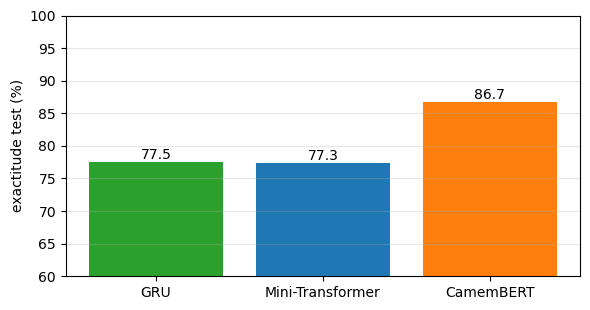

In [19]:
def agreger(res, nom):
    d = pd.DataFrame(res)
    return dict(modèle=nom, paramètres=int(d.params.iloc[0]),
                test=f"{100 * d.test.mean():.1f}" + (f" ± {100 * d.test.std():.1f}" if len(d) > 1 else ""),
                iot=f"{100 * d.iot.mean():.1f}" + (f" ± {100 * d.iot.std():.1f}" if len(d) > 1 else ""),
                époques=f"{d.epoque.mean():.0f}", temps_s=f"{d.duree.mean():.0f}")
tab = pd.DataFrame([agreger(res_gru, "GRU (séance 4)"), agreger(res_mt, "Mini-Transformer"), agreger([res_cam], "CamemBERT-base")])
print(f"Exactitude (%) sur les 2 974 phrases du test et sur les 220 phrases iot_* ; GRU et mini-Transformer : moyenne de 3 graines ; périphérique {DEVICE}")
print(tab.to_string(index=False))
gain = 100 * (res_cam["test"] - pd.DataFrame(res_mt).test.mean())
print(f"\nle pré-entraînement apporte {gain:.1f} points d'exactitude sur le mini-Transformer, pour un modèle {res_cam['params'] / res_mt[0]['params']:.0f} fois plus gros")

fig, ax = plt.subplots(figsize=(6, 3.2))
noms = ["GRU", "Mini-Transformer", "CamemBERT"]
vals = [100 * pd.DataFrame(res_gru).test.mean(), 100 * pd.DataFrame(res_mt).test.mean(), 100 * res_cam["test"]]
ax.bar(noms, vals, color=["tab:green", "tab:blue", "tab:orange"])
for k, v in enumerate(vals):
    ax.text(k, v + 0.5, f"{v:.1f}", ha="center")
ax.set_ylim(60, 100); ax.set_ylabel("exactitude test (%)"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

#### Ce que regarde CamemBERT

Une heatmap de l'attention de la dernière couche (moyenne des 12 têtes) sur « allume la lumière du salon » : c'est une **observation**, pas une explication causale. Chaque ligne est un token qui regarde ; `<s>` est le token de classification.

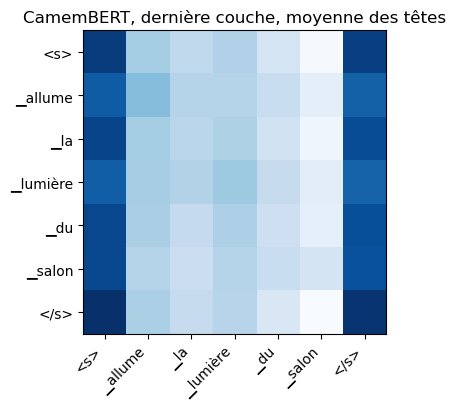

intention prédite pour cette phrase : [('iot_hue_lightup', 0.294), ('iot_hue_lightchange', 0.195), ('iot_hue_lightdim', 0.147)]


In [20]:
phrase = "allume la lumière du salon"
e = tok(phrase, return_tensors="pt").to(DEVICE)
cam.eval()
try:
    cam.set_attn_implementation("eager")                      # l'implémentation rapide (sdpa) ne renvoie pas les poids d'attention
except Exception:
    pass
with torch.no_grad():
    sortie = cam(**e, output_attentions=True)
assert sortie.attentions is not None and sortie.attentions[-1] is not None, "poids d'attention indisponibles"
A_cam = sortie.attentions[-1][0].mean(0).cpu().numpy()        # dernière couche, moyenne des têtes : n x n
sous_mots = tok.convert_ids_to_tokens(e["input_ids"][0])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(A_cam, cmap="Blues")
ax.set_xticks(range(len(sous_mots))); ax.set_xticklabels(sous_mots, rotation=45, ha="right"); ax.set_yticks(range(len(sous_mots))); ax.set_yticklabels(sous_mots)
ax.set_title("CamemBERT, dernière couche, moyenne des têtes")
plt.tight_layout(); plt.show()
probas = F.softmax(sortie.logits[0].float().cpu(), dim=0)
print("intention prédite pour cette phrase :", [(INTENTS[i], round(float(probas[i]), 3)) for i in probas.argsort(descending=True)[:3]])

### B8. (Optionnel) De la voix à l'intention : Whisper tiny, puis CamemBERT

Chaîne : **WAV → Whisper tiny → texte → CamemBERT fine-tuné → intention**. Pour utiliser **votre** voix, enregistrez un WAV (quelques secondes, « allume la lumière du salon »), importez-le dans Colab et renseignez `FICHIER_WAV`. **Sans fichier**, la phrase est synthétisée avec le modèle `facebook/mms-tts-fra` : c'est de la parole artificielle, plus propre qu'une vraie voix. Si une étape échoue (réseau, mémoire), le notebook continue.

In [21]:
FICHIER_WAV = None        # exemple : "/content/ma_voix.wav"
PHRASE_VOIX = "allume la lumière du salon"
try:
    from transformers import pipeline
    if FICHIER_WAV is not None:
        import soundfile as sf
        audio, sr = sf.read(FICHIER_WAV)
        audio = audio.mean(axis=1) if audio.ndim > 1 else audio
        if sr != 16000:
            import torchaudio
            audio = torchaudio.functional.resample(torch.tensor(audio, dtype=torch.float32), sr, 16000).numpy()
        origine_audio = f"fichier {FICHIER_WAV}"
    else:
        from transformers import VitsModel
        tok_tts = AutoTokenizer.from_pretrained("facebook/mms-tts-fra")
        tts = VitsModel.from_pretrained("facebook/mms-tts-fra").eval()
        with torch.no_grad():
            audio = tts(**tok_tts(PHRASE_VOIX, return_tensors="pt")).waveform[0].numpy()
        sr, origine_audio = tts.config.sampling_rate, "synthèse MMS-TTS (parole artificielle)"
        del tts
    print(f"audio : {origine_audio}, {len(audio) / sr:.1f} s à {sr} Hz")
    asr = pipeline("automatic-speech-recognition", model="openai/whisper-tiny", device=-1)
    texte = asr({"raw": np.asarray(audio, dtype=np.float32), "sampling_rate": sr}, generate_kwargs={"language": "french", "task": "transcribe"})["text"].strip()
    print("Whisper tiny ->", repr(texte), f"| paramètres : {nb_params(asr.model):,}".replace(",", " "))
    ids_v, mask_v = encoder_cam(pd.DataFrame({"utt": [texte]}))
    cam.eval()
    with torch.no_grad():
        p = F.softmax(cam(input_ids=ids_v.to(DEVICE), attention_mask=mask_v.to(DEVICE)).logits[0].float().cpu(), dim=0)
    print("intention :", [(INTENTS[i], round(float(p[i]), 3)) for i in p.argsort(descending=True)[:3]])
except Exception as e:
    print("Étape optionnelle non exécutée :", type(e).__name__, str(e)[:200])

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

audio : synthèse MMS-TTS (parole artificielle), 2.2 s à 16000 Hz


Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

Whisper tiny -> 'Alim, la lumière du salon.' | paramètres : 37 760 640


intention : [('iot_hue_lightup', 0.255), ('iot_hue_lightchange', 0.177), ('iot_hue_lightdim', 0.159)]


### B9. Et sur cible embarquée ?

Les trois modèles face au STM32F446 (Cortex-M4, 180 MHz, 512 Ko de Flash, 128 Ko de SRAM). La table d'embeddings se lit par index, sans calcul : on la sépare des blocs. Whisper tiny : 39 M paramètres d'après l'article (PyTorch en compte 37,8 M, voir B8) ; on garde 39 M, l'ordre de grandeur étant le même.

In [22]:
FLASH = 512 * 1024
mt0 = modeles_mt[0]
n_emb, n_blocs = nb_params(mt0.emb), nb_params(mt0.blocs)
print(f"{'modèle':36s}{'paramètres':>12s}{'float32':>11s}{'int8':>10s}{'int8 / Flash':>14s}")
for nom, n in [("Mini-Transformer (complet)", nb_params(mt0)), ("  dont embeddings", n_emb), ("  dont 2 blocs", n_blocs),
               ("Whisper tiny", 39_000_000), ("CamemBERT-base", res_cam["params"])]:
    n_txt = f"{n:,d}".replace(",", " ")
    print(f"{nom:36s}{n_txt:>12s}{4 * n / 1e6:8.2f} Mo{n / 1e6:7.2f} Mo{n / FLASH:13.1f}x")
print("\n(un rapport int8 / Flash supérieur à 1 signifie que les poids ne tiennent pas dans la Flash du STM32F446)")
n_t, d_t = 32, 128
mac_couche = 4 * n_t * d_t ** 2 + 2 * n_t ** 2 * d_t + 8 * n_t * d_t ** 2
print(f"\nmini-Transformer, n = {n_t} : {2 * mac_couche / 1e6:.1f} M MAC pour 2 couches, {2 * mac_couche / 180e6 * 1e3:.0f} ms à 180 MHz (1 MAC par cycle, borne basse)")

modèle                                paramètres    float32      int8  int8 / Flash
Mini-Transformer (complet)             1 180 220    4.72 Mo   1.18 Mo          2.3x
  dont embeddings                        775 680    3.10 Mo   0.78 Mo          1.5x
  dont 2 blocs                           396 544    1.59 Mo   0.40 Mo          0.8x
Whisper tiny                          39 000 000  156.00 Mo  39.00 Mo         74.4x
CamemBERT-base                       110 668 092  442.67 Mo 110.67 Mo        211.1x

(un rapport int8 / Flash supérieur à 1 signifie que les poids ne tiennent pas dans la Flash du STM32F446)

mini-Transformer, n = 32 : 13.1 M MAC pour 2 couches, 73 ms à 180 MHz (1 MAC par cycle, borne basse)


## Partie C — Exercices de validation

Chaque fonction ci-dessous renvoie `None` : le vérificateur affiche alors **« À compléter »**. Complétez-les, puis relancez `verifier_tout()`. Le corrigé est à la fin du notebook : essayez d'abord !

In [23]:
def verifier(nom, valeur, attendu, tol=1e-3):
    if valeur is None:
        print(f"{nom} : À compléter")
        return
    try:
        ok = np.allclose(np.asarray(valeur, dtype=float), np.asarray(attendu, dtype=float), atol=tol)
    except Exception:
        ok = False
    if ok:
        print(f"{nom} : Correct")
    else:
        print(f"{nom} : Incorrect (obtenu {np.round(np.asarray(valeur, dtype=float), 4)}, attendu {attendu})")

def verifier_tout():
    verifier("Exercice 1 — poids d'attention (ligne « allume »)", None if attention_poids(Q, K) is None else attention_poids(Q, K)[0], [0.1636, 0.1636, 0.6728])
    verifier("Exercice 2 — encodage positionnel (pos 1, d 4)", pe_vecteur(1, 4), [0.8415, 0.5403, 0.0100, 1.0])
    verifier("Exercice 3 — paramètres d'un bloc (d = 768)", params_bloc(768), 7077888)
    verifier("Exercice 4 — softmax causal (ligne 3)", softmax_causal(S4)[2] if softmax_causal(S4) is not None else None, [0.0900, 0.2447, 0.6652, 0.0])
    verifier("Exercice 5 — mémoire d'attention (n = 32, 4 têtes, float32)", memoire_attention(32, 4, 4), 16384)

**Exercice 1 — Poids d'attention.** Complétez `attention_poids(Q, K)` : la matrice $\mathrm{softmax}(QK^\top/\sqrt{d_k})$, ligne par ligne. Vérification : la ligne « allume » de l'exemple A1.

In [24]:
def attention_poids(Q, K):
    # À compléter
    return None

**Exercice 2 — Encodage positionnel.** Complétez `pe_vecteur(pos, d)` : le vecteur $\mathrm{PE}(pos, \cdot)$ de dimension `d`, sinus aux indices pairs, cosinus aux indices impairs. Puis, en dehors du vérificateur : pour $d = 64$, à partir de quelle position la composante la plus lente a-t-elle fait un demi-tour ?

In [25]:
def pe_vecteur(pos, d):
    # À compléter
    return None

**Exercice 3 — Paramètres d'un bloc.** Complétez `params_bloc(d)` : le nombre de paramètres d'un bloc Transformer, biais et LayerNorm négligés, avec un FFN de largeur $4d$. Puis, en dehors du vérificateur : combien pour 12 blocs de $d = 768$ ?

In [26]:
def params_bloc(d):
    # À compléter
    return None

**Exercice 4 — Softmax causal.** Complétez `softmax_causal(S)` : la matrice de poids après ajout du masque causal (les positions futures valent $-\infty$ avant le softmax). Vérification : la ligne 3 de l'exemple A7.

In [27]:
def softmax_causal(S):
    # À compléter
    return None

**Exercice 5 — Mémoire de l'attention.** Complétez `memoire_attention(n, octets, tetes)` : la mémoire, en octets, des matrices $n \times n$ d'une couche. Puis, en dehors du vérificateur : à quelle longueur $n$ dépasse-t-on les 128 Ko de SRAM du STM32F446 avec 4 têtes en float32 ?

In [28]:
def memoire_attention(n, octets, tetes):
    # À compléter
    return None

In [29]:
verifier_tout()

Exercice 1 — poids d'attention (ligne « allume ») : À compléter
Exercice 2 — encodage positionnel (pos 1, d 4) : À compléter
Exercice 3 — paramètres d'un bloc (d = 768) : À compléter
Exercice 4 — softmax causal (ligne 3) : À compléter
Exercice 5 — mémoire d'attention (n = 32, 4 têtes, float32) : À compléter


## Corrigé

Essayez d'abord les exercices ! Cette section définit les solutions, puis relance le vérificateur.

In [30]:
def attention_poids(Q, K):
    Q, K = np.asarray(Q, dtype=float), np.asarray(K, dtype=float)
    return softmax_np(Q @ K.T / math.sqrt(Q.shape[-1]))

def pe_vecteur(pos, d):
    v = np.zeros(d)
    for i in range(d // 2):
        v[2 * i] = math.sin(pos / 10000 ** (2 * i / d)); v[2 * i + 1] = math.cos(pos / 10000 ** (2 * i / d))
    return v                                   # d = 64 : omega_min = 1/10000^(62/64) ≈ 1,3e-4, demi-tour à pos = pi/omega ≈ 24 000

def params_bloc(d):
    return 4 * d * d + 2 * d * (4 * d)         # attention 4 d^2 + FFN 8 d^2 = 12 d^2 ; 12 blocs de d = 768 : 84 934 656

def softmax_causal(S):
    S = np.asarray(S, dtype=float)
    return softmax_np(S + np.triu(np.full(S.shape, -np.inf), k=1))

def memoire_attention(n, octets, tetes):
    return n * n * octets * tetes              # 4 têtes en float32 : n^2 x 16 octets = 131 072 pour n = 90,5, soit n = 91

verifier_tout()

Exercice 1 — poids d'attention (ligne « allume ») : Correct
Exercice 2 — encodage positionnel (pos 1, d 4) : Correct
Exercice 3 — paramètres d'un bloc (d = 768) : Correct
Exercice 4 — softmax causal (ligne 3) : Correct
Exercice 5 — mémoire d'attention (n = 32, 4 têtes, float32) : Correct


## Pour aller plus loin

- Passez de 2 à 4 blocs, ou de 4 à 8 têtes, dans le mini-Transformer : que se passe-t-il ? Combien de paramètres de plus ?
- Remplacez le *mean pooling* par un token `[CLS]` appris.
- Gelez les 10 premiers blocs de CamemBERT et n'entraînez que les 2 derniers et la tête : exactitude et temps ?
- Quantifiez le mini-Transformer en int8 (`torch.ao.quantization.quantize_dynamic`) : taille et exactitude avant et après ?
- Comparez avec `distilbert-base-multilingual-cased` : un modèle plus petit, pré-entraîné sur plusieurs langues.

## Références

- Vaswani et al. (2017), *Attention Is All You Need* ; Bahdanau et al. (2014), attention ; Devlin et al. (2018), BERT ; Radford et al. (2018, 2019), GPT.
- Martin et al. (2020), *CamemBERT* ; Sanh et al. (2019), DistilBERT ; Hinton et al. (2015), distillation ; Dosovitskiy et al. (2020), ViT ; Radford et al. (2022), Whisper.
- Su et al. (2021), RoPE ; Dao et al. (2022), FlashAttention ; FitzGerald et al. (2022), *MASSIVE*.

In [31]:
print(f"Durée d'exécution du notebook : {time.time() - T0:.0f} s")

Durée d'exécution du notebook : 1720 s
